# Audit de la base de délinquance enregistrée — niveau communal (2016-2025)

**Projet :** Compagnon Immobilier · **Auteur :** Cécile NAUDET · **Relecteur :** _ · **Date :** 17/10/2026

Base auditée : `dataset_delinquance_communale.parquet`, base communale du SSMSI (données 2016 à 2025, géographie communale au 1er janvier 2026).

## Chargement

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = Path("/home/naude/formation/projet_compagnon/data")
delinq = pd.read_parquet(data / "dataset_delinquance_communale.parquet")

pd.set_option("display.max_columns", None)
print(delinq.shape)

(5238000, 13)


# A. Identité

## 1. Source et origine

**Constat :**

La base est produite par le **SSMSI** (Service statistique ministériel de la sécurité intérieure), le service statistique du ministère de l'Intérieur. Elle repose sur les **procédures enregistrées par la police et la gendarmerie** avant leur transmission à la justice : plaintes, signalements, flagrants délits, ou faits constatés par les services eux-mêmes. Elle mesure donc la délinquance **enregistrée**, et non toute la délinquance. Son niveau dépend du dépôt de plainte, très variable selon l'atteinte : d'après les enquêtes de victimation (2011-2018), 74 % des victimes de cambriolage portent plainte, contre 12 % des victimes de violences sexuelles.

Les faits sont comptés dans la **commune où ils ont été commis**, avec deux exceptions :
- les escroqueries sont comptées au domicile de la victime, car une grande partie a lieu sur internet ;
- les infractions sur les stupéfiants comptent des personnes mises en cause, à la date où l'affaire est élucidée. Elles reflètent donc en partie l'activité des services.

La base communale donne **15 indicateurs**, chacun en **nombre** et en **taux pour 1 000 habitants** (pour 1 000 logements dans le cas des cambriolages). L'unité de compte dépend de l'indicateur : victime, infraction, véhicule ou personne mise en cause.

**Secret statistique :** une commune n'est diffusée que si plus de 5 faits ont été enregistrés pendant 3 années successives (colonne `est_diffuse` = « diff »). Sinon (« ndiff »), le nombre et le taux sont vides. À la place, la base donne la moyenne des communes non diffusées du même département (`complement_info_nombre`, `complement_info_taux`). Cette règle protège les personnes concernées et évite d'interpréter des chiffres trop petits pour être fiables.

Les données couvrent **2016 à 2025** : il n'existe pas de données communales pour 2014 et 2015. Elles sont fournies dans la **géographie communale du 1er janvier 2026**. Les chiffres d'une année sont arrêtés en avril de l'année suivante.


## 2. Dimensions, unité d'observations

**Objectif :** connaître le volume (effectifs, mémoire, temps de calcul), savoir ce que représente une ligne.


In [6]:
print(delinq.shape)
delinq.info(memory_usage="deep")
display(delinq.head(15))

# Une ligne = une commune × une année × un indicateur ?
# Si la grille est complète, le nombre de lignes est le produit des trois
n_com = delinq["CODGEO_2026"].nunique()
n_an = delinq["annee"].nunique()
n_ind = delinq["indicateur"].nunique()
print(f"{n_com} communes × {n_an} années × {n_ind} indicateurs = {n_com * n_an * n_ind:,} | lignes : {len(delinq):,}")

(5238000, 13)
<class 'pandas.DataFrame'>
RangeIndex: 5238000 entries, 0 to 5237999
Data columns (total 13 columns):
 #   Column                  Dtype   
---  ------                  -----   
 0   CODGEO_2026             str     
 1   annee                   int32   
 2   indicateur              category
 3   unite_de_compte         category
 4   nombre                  float64 
 5   taux_pour_mille         float64 
 6   est_diffuse             str     
 7   insee_pop               int32   
 8   insee_pop_millesime     int32   
 9   insee_log               int32   
 10  insee_log_millesime     int32   
 11  complement_info_nombre  float64 
 12  complement_info_taux    float64 
dtypes: category(2), float64(4), int32(5), str(2)
memory usage: 396.9 MB


,CODGEO_2026,annee,indicateur,unite_de_compte,nombre,taux_pour_mille,est_diffuse,insee_pop,insee_pop_millesime,insee_log,insee_log_millesime,complement_info_nombre,complement_info_taux
0,01001,2016,Violences physiques intrafamiliales,Victime,0.0,0.0,diff,767,2016,348,2016,NaN,NaN
1,01001,2016,Violences physiques hors cadre familial,Victime,NaN,NaN,ndiff,767,2016,348,2016,1.362069,0.959839
2,01001,2016,Violences sexuelles,Victime,0.0,0.0,diff,767,2016,348,2016,NaN,NaN
3,01001,2016,Vols avec armes,Infraction,0.0,0.0,diff,767,2016,348,2016,NaN,NaN
4,01001,2016,Vols violents sans arme,Infraction,0.0,0.0,diff,767,2016,348,2016,NaN,NaN
5,01001,2016,Vols sans violence contre des personnes,Victime entendue,NaN,NaN,ndiff,767,2016,348,2016,2.027397,2.217436
6,01001,2016,Cambriolages de logement,Infraction,NaN,NaN,ndiff,767,2016,348,2016,2.774545,6.696478
7,01001,2016,Vols de véhicule,Véhicule,NaN,NaN,ndiff,767,2016,348,2016,1.978102,1.655149
8,01001,2016,Vols dans les véhicules,Véhicule,0.0,0.0,diff,767,2016,348,2016,NaN,NaN
9,01001,2016,Vols d'accessoires sur véhicules,Véhicule,NaN,NaN,ndiff,767,2016,348,2016,1.790514,1.287312


34920 communes × 10 années × 15 indicateurs = 5,238,000 | lignes : 5,238,000


## 3. Temporalité

In [8]:
# Bornes temporelles observées
print("Première année :", delinq["annee"].min())
print("Dernière année :", delinq["annee"].max())

# Répartition des lignes par année
print("\nLignes par année :")
print(delinq["annee"].value_counts().sort_index())


Première année : 2016
Dernière année : 2025

Lignes par année :
annee
2016    523800
2017    523800
2018    523800
2019    523800
2020    523800
2021    523800
2022    523800
2023    523800
2024    523800
2025    523800
Name: count, dtype: int64


**Constat :**

La base compte **5 238 000 lignes et 13 colonnes** (397 Mo en mémoire). **Une ligne = une commune × une année × un indicateur.** La grille est complète : 34 920 codes géographiques × 10 années × 15 indicateurs, sans ligne manquante ni ligne en trop. Les 34 920 codes comprennent les communes de 2026 et les arrondissements de Paris, Lyon et Marseille.

Elle couvre **10 années, de 2016 à 2025**, avec 523 800 lignes par an (34 920 codes × 15 indicateurs).

Le masquage par secret statistique se fait **indicateur par indicateur** : une même commune peut être diffusée pour certains indicateurs et masquée pour d'autres.

**Impact projet :** les années 2014 et 2015 de DVF+ n'ont pas de délinquance. Avec une variable calculée sur l'année précédente, la délinquance ne peut décrire les prix qu'à partir de 2017.

**Action envisagée :** passer la base en format large (une ligne par commune × année, une colonne par indicateur retenu) au moment du preprocessing.

# B. Variables

# B. Variables

## 4. Dictionnaire des variables

| Variable | Signification | Type pandas | Type statistique |
|---|---|---|---|
| **Identification** | | | |
| `CODGEO_2026` | Code Insee de la commune en géographie 2026 (ou de l'arrondissement pour Paris, Lyon, Marseille) | `str` | Identifiant |
| `annee` | Année d'enregistrement des faits | `int32` | Temporelle discrète |
| `indicateur` | Type de crime ou délit (15 modalités, voir ci-dessous) | `category` | Qualitative nominale |
| `unite_de_compte` | Ce qui est compté : victime, victime entendue, infraction, véhicule, mis en cause | `category` | Qualitative nominale |
| **Mesure** | | | |
| `nombre` | Nombre de faits enregistrés dans l'unité de compte | `float64` | Quantitative discrète |
| `taux_pour_mille` | Nombre pour 1 000 habitants (pour 1 000 logements pour les cambriolages) | `float64` | Quantitative continue |
| **Secret statistique** | | | |
| `est_diffuse` | « diff » si la valeur est publiée, « ndiff » si elle est masquée | `str` | Qualitative binaire |
| `complement_info_nombre` | Nombre moyen des communes masquées du même département, même année et même indicateur | `float64` | Quantitative continue |
| `complement_info_taux` | Taux moyen des communes masquées du même département | `float64` | Quantitative continue |
| **Population de référence** | | | |
| `insee_pop` | Population municipale (recensement) | `int32` | Quantitative discrète |
| `insee_pop_millesime` | Année du recensement utilisé pour la population | `int32` | Temporelle discrète |
| `insee_log` | Nombre de logements (recensement) | `int32` | Quantitative discrète |
| `insee_log_millesime` | Année du recensement utilisé pour les logements | `int32` | Temporelle discrète |

`nombre` est un comptage, mais il est stocké en `float64` car un entier ne peut pas contenir de valeur vide (communes masquées).

**Les 15 indicateurs**

| Indicateur | Unité de compte |
|---|---|
| Violences physiques intrafamiliales | Victime |
| Violences physiques hors cadre familial | Victime |
| Violences sexuelles | Victime |
| Vols avec armes | Infraction |
| Vols violents sans arme | Infraction |
| Vols sans violence contre des personnes | Victime entendue |
| Cambriolages de logement | Infraction |
| Vols de véhicule | Véhicule |
| Vols dans les véhicules | Véhicule |
| Vols d'accessoires sur véhicules | Véhicule |
| Destructions et dégradations volontaires | Infraction |
| Usage de stupéfiants | Mis en cause |
| Usage de stupéfiants (AFD) | Mis en cause |
| Trafic de stupéfiants | Mis en cause |
| Escroqueries et fraudes aux moyens de paiement | Victime |

Les indicateurs n'ont pas tous la même unité de compte : on ne peut pas les additionner entre eux. « Usage de stupéfiants (AFD) » est une **partie** de l'usage de stupéfiants (les usages sanctionnés par une amende forfaitaire), et non un indicateur en plus.

In [10]:
# 1. Identifiant et variables temporelles
df_ident = delinq[["CODGEO_2026", "annee", "insee_pop_millesime", "insee_log_millesime"]]

# 2. Variables qualitatives
df_quali = delinq[["indicateur", "unite_de_compte", "est_diffuse"]]

# 3. Variables quantitatives discrètes (dénombrements)
df_num_discrete = delinq[["nombre", "insee_pop", "insee_log"]]

# 4. Variables quantitatives continues
df_num_quanti = delinq[["taux_pour_mille", "complement_info_nombre", "complement_info_taux"]]

print("Identifiant et temporelles :", df_ident.shape)
print("Qualitatives               :", df_quali.shape)
print("Quantitatives discrètes    :", df_num_discrete.shape)
print("Quantitatives continues    :", df_num_quanti.shape)

Identifiant et temporelles : (5238000, 4)
Qualitatives               : (5238000, 3)
Quantitatives discrètes    : (5238000, 3)
Quantitatives continues    : (5238000, 3)


indicateur
Violences physiques intrafamiliales               349200
Violences physiques hors cadre familial           349200
Violences sexuelles                               349200
Vols avec armes                                   349200
Vols violents sans arme                           349200
Vols sans violence contre des personnes           349200
Cambriolages de logement                          349200
Vols de véhicule                                  349200
Vols dans les véhicules                           349200
Vols d'accessoires sur véhicules                  349200
Destructions et dégradations volontaires          349200
Usage de stupéfiants                              349200
Usage de stupéfiants (AFD)                        349200
Trafic de stupéfiants                             349200
Escroqueries et fraudes aux moyens de paiement    349200
Homicides                                              0
Tentatives d'homicide                                  0
Usage de stupéfiants

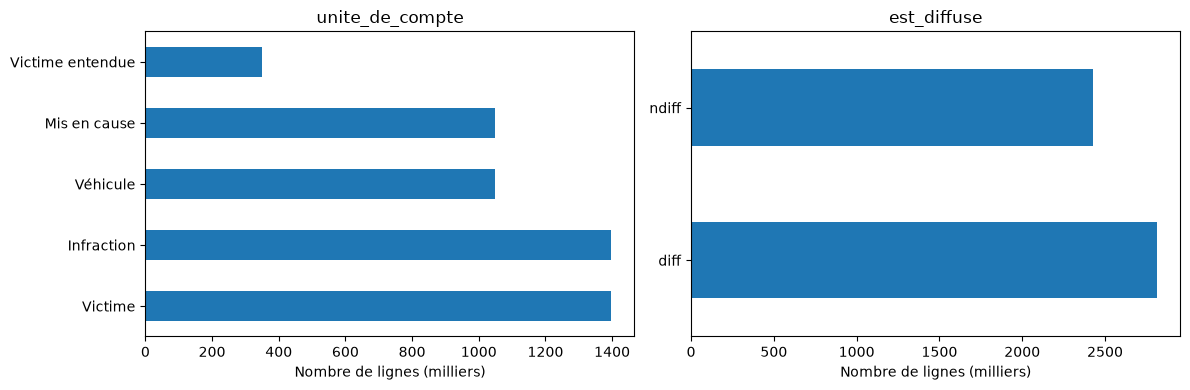

In [15]:
# Modalités et effectifs de chaque variable qualitative
for col in df_quali.columns:
    print(df_quali[col].value_counts(), "\n")

# Graphiques des deux variables qualitatives informatives
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["unite_de_compte", "est_diffuse"]):
    effectifs = df_quali[col].value_counts()
    (effectifs[effectifs > 0] / 1000).plot.barh(ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Nombre de lignes (milliers)")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

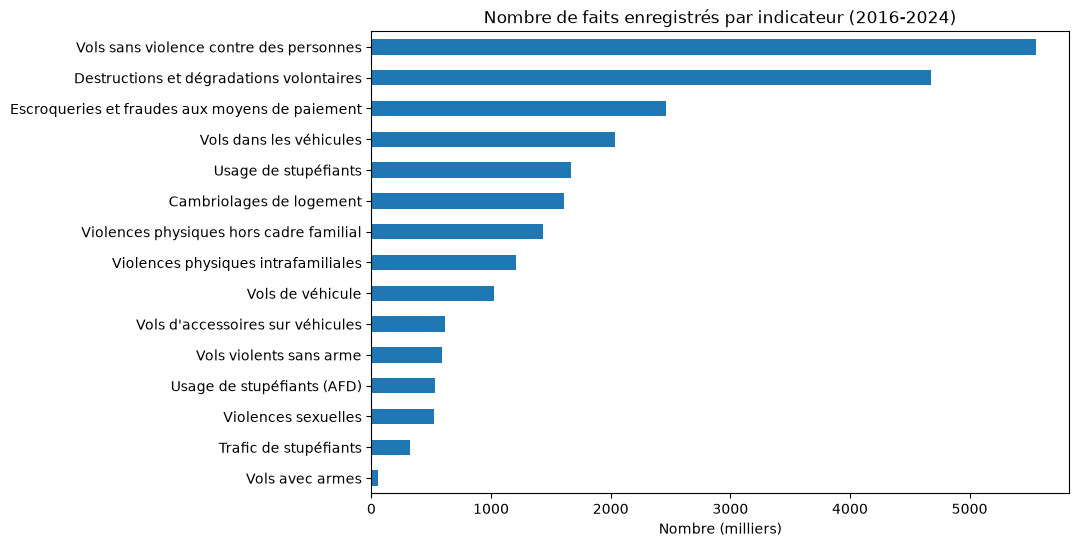

In [18]:
# Paris, Lyon, Marseille : on retire les arrondissements pour ne pas compter ces villes deux fois
sans_arr = delinq[~delinq["CODGEO_2026"].str.match(r"^(751|6938|132)")]

# 2025 est l'année de test : on la laisse de côté
sans_arr = sans_arr[sans_arr["annee"] <= 2024]

# Total des faits par indicateur, en milliers, du plus petit au plus grand
total = sans_arr.groupby("indicateur", observed=True)["nombre"].sum().sort_values() / 1000

total.plot.barh(figsize=(9, 6))
plt.title("Nombre de faits enregistrés par indicateur (2016-2024)")
plt.xlabel("Nombre (milliers)")
plt.ylabel("")
plt.show()

**Constat :**

*Variables qualitatives.*
- **`indicateur`** : 15 indicateurs, de 349 200 lignes chacun (34 920 codes × 10 années), ce qui confirme que la grille est complète. La liste des modalités de la colonne en annonce 18 : les trois autres (homicides, tentatives d'homicide, usage de stupéfiants hors AFD) ne sont publiés qu'au niveau départemental et n'ont aucune ligne dans la base communale.
- **`unite_de_compte`** : 5 unités (victime, victime entendue, infraction, véhicule, mis en cause). Les indicateurs ne se comptent pas dans la même unité : on ne peut pas les additionner entre eux.
- **`est_diffuse`** : près de la moitié des lignes sont masquées par le secret statistique (environ 2,4 millions sur 5,2 millions). Ce point est étudié dans la partie Qualité.

*Nombre de faits par indicateur (2016-2024, sans les arrondissements pour ne pas compter deux fois Paris, Lyon et Marseille).*
Deux indicateurs dominent : les vols sans violence contre des personnes (environ 5,5 millions de faits) et les destructions et dégradations volontaires (environ 4,7 millions). Les cambriolages de logement, l'indicateur le plus directement lié au logement, comptent environ 1,6 million de faits. Les vols avec armes sont très rares (quelques dizaines de milliers en neuf ans) : au niveau d'une commune ou d'un bassin de vie, ils seront presque toujours nuls ou masqués. Ces totaux sont un peu sous-estimés, car les communes masquées ne sont pas comptées.

*Variables non étudiées en détail.*
La seule information utile pour le projet est le croisement entre l'indicateur et sa mesure (nombre ou taux). Les autres variables servent à la calculer ou à l'interpréter, et ne sont donc pas décrites ici :
- `insee_pop` et `insee_log` sont la population et les logements utilisés pour calculer le taux. Leur valeur est la même pour les 15 indicateurs d'une commune ;
- `complement_info_nombre` et `complement_info_taux` ne sont remplis que pour les lignes masquées : ils sont étudiés avec les valeurs manquantes ;
- les millésimes indiquent l'année du recensement utilisé : ils serviront au recalcul des taux au bassin de vie.

**Impact projet :** tous les indicateurs ne sont pas exploitables. Les plus rares, comme les vols avec armes, seront trop souvent nuls ou masqués à l'échelle d'un bassin de vie.

**Action envisagée :** choisir les indicateurs à retenir après l'étude des valeurs manquantes, en tenant compte de leur fréquence et de leur lien avec le logement.

# C. Qualité

## 5. Doublons exacts

**Objectif :** repérer les lignes copiées, qui gonflent les effectifs.


In [19]:
# 1. Doublons exacts et doublons sur la clé commune × année × indicateur
print("Doublons exacts :", delinq.duplicated().sum())
print("Doublons sur la clé :", delinq.duplicated(subset=["CODGEO_2026", "annee", "indicateur"]).sum())

# 2. Paris, Lyon, Marseille : ville entière contre somme des arrondissements
plm = {
    "Paris":     ("75056", "751"),   # code de la ville, début des codes d'arrondissement
    "Lyon":      ("69123", "6938"),
    "Marseille": ("13055", "132"),
}
d = delinq[(delinq["annee"] == 2024) & (delinq["indicateur"] == "Cambriolages de logement")]
for ville, (code, prefixe) in plm.items():
    entiere = d[d["CODGEO_2026"] == code]
    arrond = d[d["CODGEO_2026"].str.startswith(prefixe)]
    print(f"{ville} 2024 | ville : {entiere['nombre'].sum():,.0f} cambriolages, {entiere['insee_pop'].sum():,.0f} hab. | "
          f"{len(arrond)} arrondissements : {arrond['nombre'].sum():,.0f} cambriolages, {arrond['insee_pop'].sum():,.0f} hab.")# votre code

Doublons exacts : 0
Doublons sur la clé : 0
Paris 2024 | ville : 9,235 cambriolages, 2,103,778 hab. | 20 arrondissements : 9,235 cambriolages, 2,103,778 hab.
Lyon 2024 | ville : 2,502 cambriolages, 519,127 hab. | 9 arrondissements : 2,502 cambriolages, 519,127 hab.
Marseille 2024 | ville : 4,471 cambriolages, 886,040 hab. | 16 arrondissements : 4,471 cambriolages, 886,040 hab.


**Constat :**

Aucun doublon exact et aucun doublon sur la clé commune × année × indicateur.

En revanche, Paris, Lyon et Marseille sont présentes à deux niveaux : la ville entière (75056, 69123, 13055) et ses arrondissements (20, 9 et 16). En 2024, pour les cambriolages de logement, le nombre de faits et la population de la ville sont exactement égaux à la somme de ses arrondissements : 9 235 cambriolages et 2 103 778 habitants pour Paris, 2 502 et 519 127 pour Lyon, 4 471 et 886 040 pour Marseille. Les deux niveaux décrivent donc les mêmes faits : ce sont des doublons métier.

**Impact projet :** additionner les deux niveaux compterait deux fois la délinquance de ces trois villes et fausserait tout total ou tout taux calculé au bassin de vie.

**Action envisagée :** ne jamais additionner la ville entière et ses arrondissements. Les deux niveaux sont conservés pour l'instant : le niveau retenu dépendra de la décision de l'équipe sur la maille des grandes villes (découpage par arrondissement ou non).

## 6. Valeurs manquantes

**Objectif :** mesurer l'ampleur des manquants par variable.



In [20]:
manquants = (delinq.isna().mean() * 100).round(2)
display(manquants[manquants > 0].sort_values(ascending=False))# votre code

complement_info_taux      53.69
complement_info_nombre    53.69
taux_pour_mille           46.33
nombre                    46.31
dtype: float64

In [21]:
# Lignes avec un nombre mais sans taux
ecart = delinq[delinq["nombre"].notna() & delinq["taux_pour_mille"].isna()]
print("Lignes concernées :", len(ecart))
display(ecart[["CODGEO_2026", "indicateur", "nombre", "insee_pop", "insee_log"]]
        .drop_duplicates("CODGEO_2026").head(10))

Lignes concernées : 849


,CODGEO_2026,indicateur,nombre,insee_pop,insee_log
300195,55039,Violences physiques intrafamiliales,0.0,0,0
300360,55050,Violences physiques intrafamiliales,0.0,0,0
301485,55139,Violences physiques intrafamiliales,0.0,0,1
302130,55189,Violences physiques intrafamiliales,0.0,0,0
302685,55239,Violences physiques intrafamiliales,0.0,0,0
303570,55307,Violences physiques intrafamiliales,0.0,0,0


In [22]:
# Le nombre est-il vide exactement quand la ligne est masquée ?
display(pd.crosstab(delinq["est_diffuse"], delinq["nombre"].isna().rename("nombre vide")))

# Le complément est-il rempli exactement quand la ligne est masquée ?
display(pd.crosstab(delinq["est_diffuse"], delinq["complement_info_nombre"].isna().rename("complément vide")))

nombre vide,False,True
est_diffuse,,
diff,2812128,0
ndiff,0,2425872


complément vide,False,True
est_diffuse,,
diff,0,2812128
ndiff,2425872,0


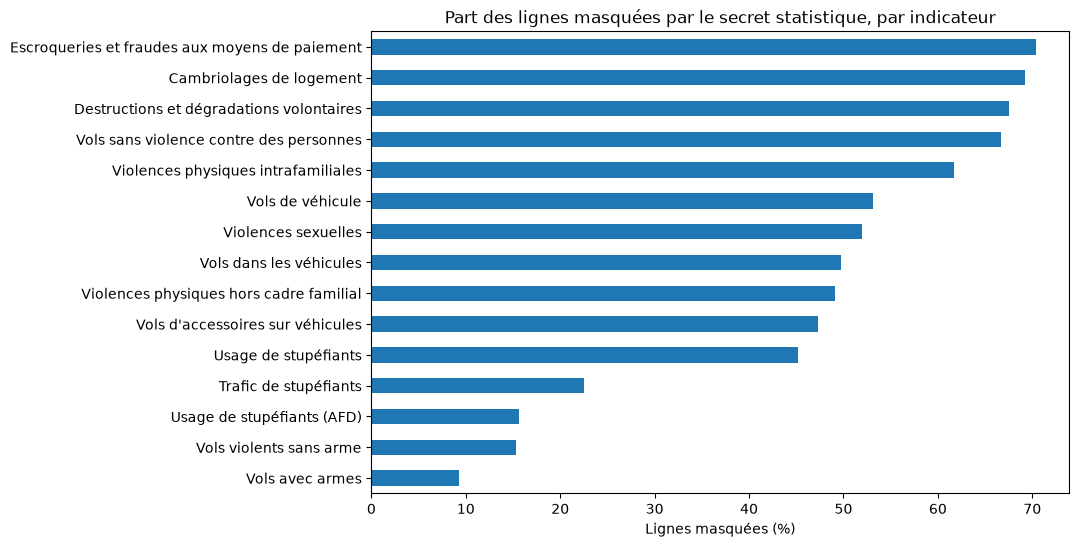

In [28]:
# Pour chaque indicateur, part des lignes diffusées et masquées (en %)
part = pd.crosstab(delinq["indicateur"], delinq["est_diffuse"], normalize="index") * 100

part["ndiff"].sort_values().plot.barh(figsize=(9, 6))
plt.title("Part des lignes masquées par le secret statistique, par indicateur")
plt.xlabel("Lignes masquées (%)")
plt.ylabel("")
plt.show()

**Constat :**

Seules quatre variables ont des valeurs manquantes :
- `nombre` (46,31 %) et `taux_pour_mille` (46,33 %) ;
- `complement_info_nombre` et `complement_info_taux` (53,69 %).

Les manquants s'expliquent entièrement par le secret statistique. Les 2 425 872 lignes masquées (`ndiff`) ont toutes un nombre vide et un complément rempli ; les 2 812 128 lignes diffusées ont toutes un nombre rempli et un complément vide. Le petit écart entre `nombre` et `taux_pour_mille` vient de six communes de la Meuse sans habitant (villages détruits pendant la bataille de Verdun) : le taux ne peut pas y être calculé.

La part de lignes masquées varie beaucoup selon l'indicateur : de 9 % pour les vols avec armes à 70 % pour les escroqueries, et 69 % pour les cambriolages de logement. Ce sont les indicateurs les plus fréquents qui sont le plus masqués. La règle de diffusion l'explique : une commune est publiée si elle a plus de 5 faits sur trois années successives, ou aucun fait pendant trois ans. Le masquage touche donc les communes qui ont quelques faits, sans en avoir assez. Pour un indicateur rare, la plupart des communes n'ont aucun fait : le zéro est publié.

Les manquants dépendent du nombre de faits lui-même, c'est-à-dire de la valeur qui manque : ils ne sont pas aléatoires.

**Impact projet :** une valeur masquée n'est pas une absence d'information : elle signifie « quelques faits ». La remplacer par 0 ou supprimer ces lignes fausserait les totaux par bassin de vie.

**Action envisagée :** au moment du preprocessing, utiliser le complément départemental (`complement_info_nombre`) pour tenir compte des faits des communes masquées dans les totaux par bassin de vie.

## 7 Distributions et valeurs extrêmes

**Objectif :** repérer les taux anormalement élevés et comprendre d'où ils viennent.



In [32]:
# Centiles du taux par indicateur (2024, communes diffusées, sans les arrondissements)
centiles = (d24.groupby("indicateur", observed=True)["taux_pour_mille"]
               .describe(percentiles=[0.50, 0.90, 0.99]).round(2))
centiles["max / p99"] = (centiles["max"] / centiles["99%"]).round(1)

display(centiles[["count", "50%", "90%", "99%", "max", "max / p99"]].sort_values("max / p99"))

,count,50%,90%,99%,max,max / p99
indicateur,,,,,,
Escroqueries et fraudes aux moyens de paiement,10344.0,4.86,7.83,10.91,32.61,3.0
Violences physiques intrafamiliales,12166.0,0.00,4.73,8.55,29.05,3.4
Cambriolages de logement,10715.0,0.00,9.40,19.15,67.87,3.5
Destructions et dégradations volontaires,11126.0,4.78,10.56,18.14,92.23,5.1
Violences sexuelles,14502.0,0.00,1.73,4.44,27.67,6.2
Vols de véhicule,15998.0,0.00,1.80,4.92,37.77,7.7
Violences physiques hors cadre familial,16975.0,0.00,2.93,7.84,74.07,9.4
Vols violents sans arme,29629.0,0.00,0.00,0.83,13.46,16.2
Vols sans violence contre des personnes,11297.0,0.00,7.93,24.62,1006.36,40.9


In [33]:
# Les 5 communes aux taux les plus élevés, pour deux indicateurs
cols = ["CODGEO_2026", "nombre", "taux_pour_mille", "insee_pop"]
for ind in ["Trafic de stupéfiants", "Vols sans violence contre des personnes"]:
    print(ind)
    display(d24[d24["indicateur"] == ind].nlargest(5, "taux_pour_mille")[cols])

Trafic de stupéfiants


,CODGEO_2026,nombre,taux_pour_mille,insee_pop
4711663,95527,510.0,190.725505,2674
4484878,54242,8.0,28.268551,283
4578283,66024,147.0,26.790596,5487
4704163,90062,7.0,24.822695,282
4713358,97307,779.0,21.335451,36512


Vols sans violence contre des personnes


,CODGEO_2026,nombre,taux_pour_mille,insee_pop
4711655,95527,2691.0,1006.357517,2674
4458980,50353,12.0,521.739130,23
4646960,77518,30.0,123.966942,242
4402970,38191,154.0,123.794212,1244
4623560,73257,433.0,123.785020,3498


**Constat :**

L'analyse porte sur 2024, dernière année hors test, pour avoir une ligne par commune. Les arrondissements sont retirés pour ne pas compter deux fois Paris, Lyon et Marseille. Seules les communes diffusées sont prises en compte. Les distributions sont décrites par un tableau de centiles plutôt que par des boîtes à moustaches : avec autant de zéros, les boîtes sont écrasées sur 0 et illisibles.

*Une majorité de zéros.* Pour 13 indicateurs sur 15, le taux médian vaut 0 : plus de la moitié des communes diffusées n'ont enregistré aucun fait en 2024. Seuls les escroqueries (médiane 4,9 pour 1 000) et les destructions et dégradations (4,8) ont une médiane non nulle. Pour quatre indicateurs (vols violents sans arme, usage de stupéfiants AFD, trafic de stupéfiants, vols avec armes), même le 90e centile vaut 0. Les vols avec armes sont nuls jusqu'au 99e centile.

*Des valeurs extrêmes très élevées.* Le rapport entre le maximum et le 99e centile va de 3 (escroqueries) à 160 (trafic de stupéfiants). Ce rapport est toutefois peu parlant pour les indicateurs presque toujours nuls : quand le 99e centile est proche de 0, le rapport devient très grand, voire infini pour les vols avec armes.

Les taux les plus élevés concernent des communes peu peuplées où passent beaucoup de personnes qui n'y habitent pas : Roissy-en-France (aéroport Charles-de-Gaulle, 2 674 habitants), avec 1 006 vols sans violence et 191 mis en cause pour trafic de stupéfiants pour 1 000 habitants, ou le Mont-Saint-Michel (23 habitants, 522 vols pour 1 000). Ce ne sont pas des erreurs, mais ces taux ne mesurent pas le risque pour les habitants.

**Impact projet :** le taux communal est instable dans les petites communes et trompeur dans les lieux très fréquentés. Il ne peut pas être utilisé tel quel. Les indicateurs presque toujours nuls (vols avec armes, vols violents sans arme, trafic de stupéfiants) apporteront peu d'information.

**Action envisagée :** recalculer les taux au bassin de vie, en additionnant les nombres de faits et les populations des communes. Les communes y pèsent selon leur taille, ce qui limite l'effet des valeurs extrêmes. Retenir en priorité les indicateurs fréquents et liés au cadre de vie.

### Test des bassins de vie

In [35]:
# Table de correspondance : un bassin de vie par code commune 2026
liaison = pd.read_csv(data / "dataset_cible" / "bv_liaison_2022.csv", dtype=str, index_col=0)
liaison_2026 = liaison[["CODGEO_2026", "BV2022"]].drop_duplicates()

bv = d24.merge(liaison_2026, on="CODGEO_2026", how="left", validate="many_to_one")

# Commune masquée : on remplace le nombre vide par la moyenne départementale des communes masquées
bv["nombre_estime"] = bv["nombre"].fillna(bv["complement_info_nombre"])

# Le taux des cambriolages se calcule pour 1 000 logements, les autres pour 1 000 habitants
bv["denominateur"] = np.where(bv["indicateur"] == "Cambriolages de logement",
                              bv["insee_log"], bv["insee_pop"])

# Somme des faits et des habitants (ou logements) par bassin, puis taux
taux_bv = bv.groupby(["BV2022", "indicateur"], observed=True)[["nombre_estime", "denominateur"]].sum()
taux_bv["taux_pour_mille"] = taux_bv["nombre_estime"] / taux_bv["denominateur"] * 1000

# Même tableau de centiles qu'au niveau communal
centiles_bv = (taux_bv.groupby("indicateur", observed=True)["taux_pour_mille"]
                      .describe(percentiles=[0.50, 0.90, 0.99]).round(2))
centiles_bv["max / p99"] = (centiles_bv["max"] / centiles_bv["99%"]).round(1)
display(centiles_bv[["count", "50%", "90%", "99%", "max", "max / p99"]].sort_values("max / p99"))

,count,50%,90%,99%,max,max / p99
indicateur,,,,,,
Cambriolages de logement,1707.0,4.87,8.23,12.35,17.64,1.4
Destructions et dégradations volontaires,1707.0,6.26,9.29,13.61,18.93,1.4
Vols d'accessoires sur véhicules,1707.0,0.93,2.05,4.00,5.93,1.5
Escroqueries et fraudes aux moyens de paiement,1707.0,5.40,7.29,9.44,15.09,1.6
Vols de véhicule,1707.0,1.28,2.59,4.48,7.40,1.7
Violences sexuelles,1707.0,1.75,2.69,4.03,7.17,1.8
Violences physiques hors cadre familial,1707.0,2.09,3.78,6.15,11.68,1.9
Violences physiques intrafamiliales,1707.0,3.24,5.00,7.14,13.24,1.9
Vols violents sans arme,1707.0,0.14,0.39,1.16,3.78,3.3


*Test au bassin de vie.* Les taux ont été recalculés pour les 1 707 bassins de vie, en additionnant les faits et les habitants (ou les logements pour les cambriolages) des communes de chaque bassin. Pour les communes masquées, le nombre a été remplacé par la moyenne départementale des communes masquées (`complement_info_nombre`). Au bassin de vie, aucun indicateur n'a plus de médiane nulle, et le rapport entre le maximum et le 99e centile tombe à 1,4 à 10,7, contre 3 à 160 au niveau communal. Les cambriolages deviennent l'indicateur le plus régulier (maximum 17,6 pour 1 000 logements, contre 67,9 par commune). Les indicateurs sur les stupéfiants gardent des valeurs élevées dans quelques bassins : ils dépendent surtout de l'activité des services de police.

**Action envisagée :** travailler sur des taux recalculés au bassin de vie, en tenant compte des communes masquées par le complément départemental. Retenir en priorité les indicateurs fréquents et stables, comme les cambriolages et les destructions et dégradations.

# Synthèse du premier niveau d'audit — Délinquance enregistrée

### Constat

La base de délinquance du SSMSI est une source pertinente pour décrire l'insécurité dans les communes. Elle est administrative : elle compte les crimes et délits enregistrés par la police et la gendarmerie, et non toute la délinquance. Son niveau dépend du dépôt de plainte, plus fréquent pour les cambriolages (74 %) que pour les violences sexuelles (12 %).

La base compte **5 238 000 lignes (une commune × une année × un indicateur) et 13 variables**. La grille est complète : 34 920 codes géographiques (communes de 2026 et arrondissements de Paris, Lyon et Marseille), 10 années de 2016 à 2025 et 15 indicateurs. Il n'existe pas de données communales pour 2014 et 2015.

L'examen de la base montre une qualité satisfaisante :
- aucun doublon exact ni sur la clé commune × année × indicateur ;
- Paris, Lyon et Marseille sont présentes à deux niveaux, la ville entière et ses arrondissements, qui décrivent exactement les mêmes faits : ce sont des doublons métier ;
- les valeurs manquantes s'expliquent entièrement par le **secret statistique**. 46 % des lignes sont masquées (de 9 % à 70 % selon l'indicateur), et la base fournit pour elles la moyenne départementale des communes masquées. Le taux manque aussi pour six villages détruits de la Meuse, sans habitant.

Au niveau communal, les taux sont difficiles à utiliser. Pour 13 indicateurs sur 15, la majorité des communes n'enregistre aucun fait. Quelques communes peu peuplées mais très fréquentées ont des taux extrêmes, comme Roissy-en-France (aéroport) ou le Mont-Saint-Michel. Au bassin de vie, les taux deviennent stables : plus aucune médiane nulle, et des valeurs extrêmes beaucoup moins isolées.

### Conséquences pour le projet

- **Maille :** recalculer les taux au bassin de vie, en additionnant les faits et les habitants (ou les logements pour les cambriolages), et non en faisant la moyenne des taux communaux.
- **Communes masquées :** les remplacer par le complément départemental plutôt que par 0 ou par une suppression.
- **Paris, Lyon, Marseille :** ne jamais additionner la ville entière et ses arrondissements. Le niveau retenu dépendra de la décision sur la maille des grandes villes.
- **Période :** la délinquance ne peut décrire les prix qu'à partir de 2017 si l'on utilise l'année précédente. Les chiffres d'une année ne sont arrêtés qu'en avril de l'année suivante, ce qui compte pour éviter d'utiliser une information pas encore connue.
- **Indicateurs :** retenir en priorité les indicateurs fréquents, stables au bassin de vie et liés au cadre de vie, comme les cambriolages de logement et les destructions et dégradations. Les indicateurs sur les stupéfiants mesurent surtout l'activité des services, et les escroqueries sont comptées au domicile de la victime : ils décrivent mal le quartier.

